In [12]:
root = "M://Diploma/experiments/vesuvius/fragments"

### Data loading

For the baseline, we will do simple per-pixel classification. That is, we do not account for the neighborhood in any way. The only input we use are the raw pixel values from IR/CT.

Since fitting all 65 CT layers into RAM is infeasible (takes up more than 100 GB), here we will also select the most useful of those for further experiments, so that we do not have to worry about implementing models in external memory.

In [13]:
import numpy
import typing
import warnings
import PIL.Image

warnings.filterwarnings("ignore", category=PIL.Image.DecompressionBombWarning)

def load_fragment(fragment: int, depths: typing.Optional[typing.List[int]]):
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png")) > 0
    pixels = numpy.flatnonzero(mask)
    ink = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")).ravel()[pixels] > 0

    if depths is None:
        ir = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/ir.png")).ravel()[pixels]
        return numpy.expand_dims(ir, 1), ink

    ct = numpy.empty((len(pixels), len(depths)), dtype=numpy.float32)
    for i, depth in enumerate(depths):
        ct[:, i] = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/surface_volume/{depth:02d}.tif")).ravel()[pixels]
    return ct, ink

def load_fragments(fragments, depths: typing.Optional[typing.List[int]]):
    values = list(load_fragment(fragments[0], depths))
    for fragment in fragments[1:]:
        fragment_values = load_fragment(fragment, depths)
        for i in range(len(values)):
            values[i] = numpy.concatenate([ values[i], fragment_values[i] ])
    return values

In [14]:
train_X, train_y = load_fragments([1, 2, 3], depths=None)
test_X, test_y = load_fragments([4], depths=None)

### Evaluation metrics

The main metric used in the competition is the $F_{0.5}$ score defined as follows:
$$ F_{0.5} = \dfrac{1.25 pr}{0.25 p + r} = \dfrac{1.25 TP}{1.25TP + FP + 0.25FN} $$
This metric scores precision higher than recall, which is designed to improve the ability to form coherent characters out of detected ink areas.

Additionally, for a more comprehensive evaluation, we compute the other typical segmentation metrics: per-pixel accuracy, precison, recall, F1-score, ROC-AUC, and Jaccard score.

For the leaderboard, the competition uses additional private data, which is not available in this project. To circumvent this, we will use Fragment 4 as a held-out test object used for evaluation. The results should generally reflect the scores in the competition, although direct comparison to the metrics reported there is not possible.

In [15]:
import numpy
import sklearn.metrics
import matplotlib.pyplot as plt

def estimate_quality(pred_proba: numpy.ndarray, masks: numpy.ndarray) -> dict:
    scores = pred_proba.flatten()
    preds = (scores >= 0.5).astype(numpy.int8)
    targets = masks.flatten().astype(numpy.int8)
    return {
        "F0.5": sklearn.metrics.fbeta_score(targets, preds, beta=0.5, zero_division=0),
        "Accuracy": sklearn.metrics.accuracy_score(targets, preds),
        "AUC-ROC": sklearn.metrics.roc_auc_score(targets, scores),
        "Precision": sklearn.metrics.precision_score(targets, preds, zero_division=0),
        "Recall": sklearn.metrics.recall_score(targets, preds, zero_division=0),
        "F1-score": sklearn.metrics.f1_score(targets, preds, zero_division=0),
        "Jaccard score": sklearn.metrics.jaccard_score(targets, preds, zero_division=0),
    }

def plot_prediction(pred_proba: numpy.ndarray, fragment: int, ax):
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png")) > 0
    prediction = numpy.zeros(mask.shape, dtype=bool)
    prediction[mask] = pred_proba.ravel() >= 0.5

    if ax is None:
        target = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")) > 0
        fig, axes = plt.subplots(1, 2, figsize=(4, 3))
        axes[0].imshow(target, cmap="gray", vmin=0, vmax=1)
        axes[0].set_title("Ink target")
        axes[1].imshow(prediction, cmap="gray", vmin=0, vmax=1)
        axes[1].set_title("Predicted ink")
        for ax in axes:
            ax.axis("off")
        fig.tight_layout()
        plt.show()
        plt.close(fig)
    else:
        ax.imshow(prediction, cmap="gray", vmin=0, vmax=1)
        ax.set_title("Predicted ink")
        ax.axis("off")

In all the following experiments, we explore two predictions: one formed from the infrared scans, and one from the 65 layers of the CT scans. The final evaluation matching the competition is only the latter one, yet the easier IR task is a simpler one that might give us some insight into the dataset and help devise a model for the harder part.

For this notebook, we also perform multiple CT experiments with different subsets of layers to find the ones that have no useful information and can be discarded from further experiments for performance reasons.
- Every second layer
- Every third layer
- Every fourth layer
- Layers 0 - 15: inner layers of the papyrus. We expect they are not useful.
- Layers 20 - 40: the writing edge. We expect they are the most useful.
- Layers 45 - 60: outer layers. We expect they are not useful.
- Layers 15 - 45: all layers except those that we assume are not uesful

### Dummy classifiers

First, let's try the simplest models that just predict constants.

In [16]:
import sklearn.dummy

def try_dummy(model: sklearn.dummy.DummyClassifier):
    train_X, train_y = load_fragments([1, 2, 3], depths=None)
    test_X, test_y = load_fragments([4], depths=None)

    model.fit(train_X, train_y)
    preds = model.predict_proba(test_X)[:, 1]
    scores = estimate_quality(preds, test_y)
    plot_prediction(preds, fragment=4, ax=None)
    return scores

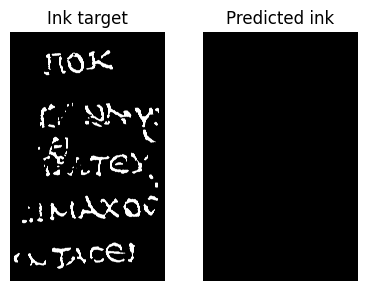

{'F0.5': 0.0,
 'Accuracy': 0.8961759286018581,
 'AUC-ROC': 0.5,
 'Precision': 0.0,
 'Recall': 0.0,
 'F1-score': 0.0,
 'Jaccard score': 0.0}

In [5]:
try_dummy(sklearn.dummy.DummyClassifier(strategy="constant", constant=0))

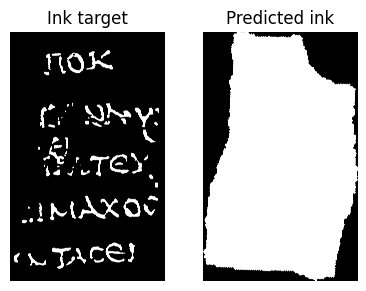

{'F0.5': 0.12649673766688765,
 'Accuracy': 0.10382407139814193,
 'AUC-ROC': 0.5,
 'Precision': 0.10382407139814193,
 'Recall': 1.0,
 'F1-score': 0.1881170633770194,
 'Jaccard score': 0.10382407139814193}

In [6]:
try_dummy(sklearn.dummy.DummyClassifier(strategy="constant", constant=1))

Expectdly, the $F_{0.5}$ score is zero. However, the class imbalance here is obvious: only 10% of pixels are labeled as having inc.

### Basic models

In [17]:
import catboost
import sklearn.tree
import sklearn.ensemble
import sklearn.linear_model
import sklearn.preprocessing

models = {
    "Decision stump": sklearn.tree.DecisionTreeClassifier(
        class_weight={0: 1, 1: 5}, max_depth=1, random_state=42
    ),
    "Logistic regression": sklearn.linear_model.LogisticRegression(
        class_weight={0: 1, 1: 5}, random_state=42, n_jobs=1
    ),
    "Decision tree": sklearn.tree.DecisionTreeClassifier(
        class_weight={0: 1, 1: 5}, max_depth=7, random_state=42
    ),
    "Random forest": sklearn.ensemble.RandomForestClassifier(
        class_weight={0: 1, 1: 5}, max_depth=7, max_samples=0.05, random_state=42, n_jobs=1, verbose=0
    ),
    "Gradient boosting": sklearn.ensemble.HistGradientBoostingClassifier(
        class_weight={0: 1, 1: 5}, max_depth=4, random_state=42, verbose=0
    ),
    "CatBoost": catboost.CatBoostClassifier(
        class_weights=[1, 5], iterations=100, depth=4, random_seed=42, verbose=False
    ),
}

In [18]:
import pandas

def evaluate(model_name: str, *data):
    train_X, train_y, test_X, test_y = data
    model = sklearn.base.clone(models[model_name]).fit(train_X, train_y)
    return model, estimate_quality(model.predict_proba(test_X)[:, 1], test_y)

def run_experiment(experiment, depths):
    train_X, train_y = load_fragments([1, 2, 3], depths=depths)
    test_X, test_y = load_fragments([4], depths=depths)

    ss = sklearn.preprocessing.StandardScaler(copy=False)
    train_X = ss.fit_transform(train_X)
    test_X = ss.transform(test_X)

    runs, trained_models = [], []
    for name in models.keys():
        model, result = evaluate(name, train_X, train_y, test_X, test_y)
        runs.append({'Model': name, 'Experiment': experiment, **result})
        print(f"{name}: F0.5={result['F0.5']:.4f}")
        trained_models.append(model)
    return trained_models, pandas.DataFrame(runs)

In [ ]:
def draw_feature_importance(importances, feature_names, title):
    print('Most important:', numpy.array(feature_names)[numpy.argsort(numpy.abs(importances))[::-1]])
    plt.figure(figsize=(6, 2))
    plt.plot(feature_names, importances)
    plt.xlabel("Feature index (layer)")
    plt.ylabel("Importance")
    plt.title(title)
    plt.show()

def analyze(trained_models, feature_names):
    print("DECISION STUMP")
    plt.figure(figsize=(6, 3))
    sklearn.tree.plot_tree(trained_models[0])
    plt.show()
    
    print("LOGISTIC REGRESSION")
    coef = e4_trained_models[1].coef_[0]
    coef_df = pandas.DataFrame({"feature name": feature_names, "weight": coef})
    display(coef_df.set_index("feature name").transpose())
    print('Intercept:', e4_trained_models[1].intercept_[0])
    draw_feature_importance(coef, feature_names, "Logistic regression")
    
    print("DECISION TREE")
    plt.figure(figsize=(10, 3))
    sklearn.tree.plot_tree(trained_models[2], max_depth=1)
    plt.show()
    draw_feature_importance(trained_models[2].feature_importances_, feature_names, "Decision tree")
    
    print("RANDOM FOREST")
    draw_feature_importance(trained_models[3].feature_importances_, feature_names, "Random forest")

    print("CATBOOST")
    draw_feature_importance(trained_models[5].feature_importances_, feature_names, "CatBoost")


#### Infrared

In [ ]:
ir_trained_models, ir_runs = run_experiment("IR", None)

Decision stump: F0.5=0.5083
Logistic regression (C=0.1): F0.5=0.5696
Logistic regression (C=1.0): F0.5=0.5696
Logistic regression (C=10.0): F0.5=0.5696
Decision tree (depth=5): F0.5=0.5512
Decision tree (depth=10): F0.5=0.5512
Decision tree (depth=25): F0.5=0.5512
Random forest: F0.5=0.5512
Gradient boosting: F0.5=0.5512
CatBoost: F0.5=0.5512


#### CT: every 2nd layer

In [ ]:
e2_trained_models, e2_runs = run_experiment("Every_2nd", list(range(0, 65, 2)))

#### CT: every 3rd layer

In [ ]:
e3_trained_models, e3_runs = run_experiment("IR", list(range(0, 65, 3)))

#### CT: every 4th layer

In [19]:
e4_trained_models, e4_runs = run_experiment("Every_4th", list(range(0, 65, 4)))

Decision stump: F0.5=0.1302
Logistic regression: F0.5=0.1311
Decision tree: F0.5=0.1314
Random forest: F0.5=0.1324
Gradient boosting: F0.5=0.1328
CatBoost: F0.5=0.1332


,Model,Experiment,F0.5,Accuracy,AUC-ROC,Precision,Recall,F1-score,Jaccard score
0,Decision stump,Every_4th,0.130192,0.488338,0.515451,0.109332,0.549669,0.182387,0.100344
1,Logistic regression,Every_4th,0.131072,0.334993,0.520721,0.108654,0.750344,0.189821,0.104863
2,Decision tree,Every_4th,0.131416,0.321243,0.535527,0.108846,0.770463,0.190744,0.105427
3,Random forest,Every_4th,0.132442,0.284390,0.537356,0.109464,0.825816,0.193305,0.106994
4,Gradient boosting,Every_4th,0.132776,0.317886,0.541031,0.109940,0.784948,0.192867,0.106725
5,CatBoost,Every_4th,0.133222,0.325118,0.542501,0.110353,0.778868,0.193316,0.107000


DECISION STUMP


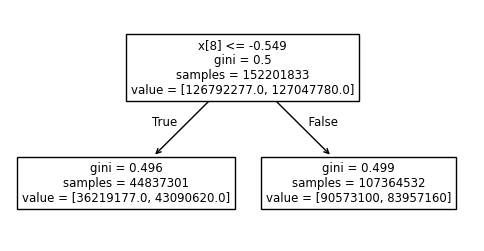

LOGISTIC REGRESSION


feature name,0,4,8,12,16,20,24,28,32,36,40,44,48,52,56,60,64
weight,0.011248,0.016428,0.021839,0.02207,0.025981,0.034742,0.024735,-0.00223,0.003229,-0.02391,-0.021812,-0.014381,-0.002991,0.000197,-0.00155,-0.00457,-0.009928


Intercept: -0.00023742185498535148
Most important: [20 16 24 36 12  8 40  4 44  0 64 60 32 48 28 56 52]


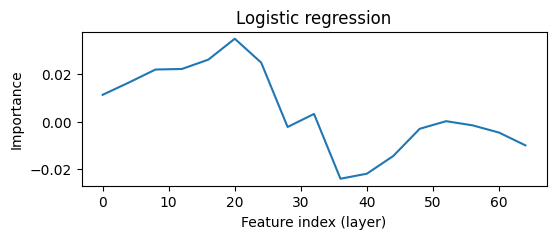

DECISION TREE


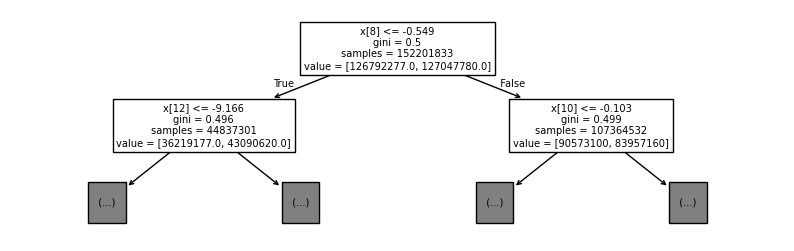

Most important: [28 16 32 40  0 48 36 24 64  8 60 20 52 12  4 44 56]


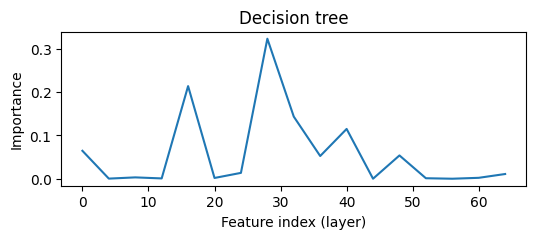

RANDOM FOREST
Most important: [32 28 36 20 24 16 12 40  4  8  0 44 64 52 60 48 56]


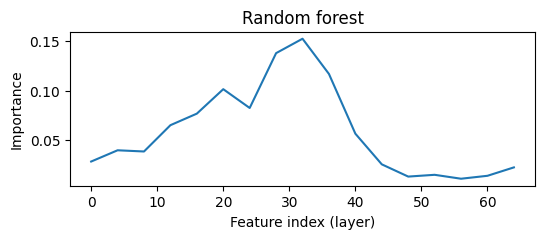

CATBOOST
Most important: [28 32 24 36  0 40 20 16  8  4 12 64 56 44 60 52 48]


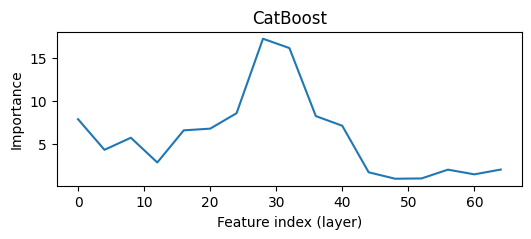

In [60]:
display(e4_runs)
analyze(e4_trained_models, list(range(0, 65, 4)))

#### CT: inner layers

In [ ]:
inner_trained_models, inner_runs = run_experiment("IR", list(range(0, 16)))

#### CT: middle layers

In [ ]:
inner_trained_models, inner_runs = run_experiment("IR", list(range(20, 41)))

#### CT: outer layers

In [ ]:
inner_trained_models, inner_runs = run_experiment("IR", list(range(45, 65)))

#### CT: expected best layers

In [ ]:
inner_trained_models, inner_runs = run_experiment("IR", list(range(15, 46)))